# Projet 9 — Petit LLM : fine-tuning QLoRA pour l'extraction d'informations en JSON (variante A)

**Question** : un petit modèle ouvert (Qwen2.5-1.5B-Instruct, 4 bits) adapté par QLoRA extrait-il mieux
les entités (personnes, organisations, lieux) au format JSON que **le même modèle avec prompt seul**
(zero-shot et few-shot), sur un jeu de test jamais vu ?

* Toute la logique est dans le paquet `src/llmx` (testé) ; ce notebook ne fait qu'orchestrer.
* Tous les hyperparamètres sont dans `configs/base.yaml`.
* Les choix (nombre d'époques, meilleure baseline) se font **sur la validation** par une règle fixée
  à l'avance (section 4) ; le **test n'est utilisé qu'une fois** par système (section 6, verrou logiciel).
* Exécution de développement archivée : `notebooks/archive/2026-11-27_validation_run.ipynb`.

## 0. Installation et environnement

In [17]:
import os, sys, pathlib

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # un seul GPU (Kaggle fournit parfois 2 x T4)
REPO_URL = "https://github.com/Aziz-Gnouma/llm-extract.git"
# Kaggle se reconnaît à sa variable d'environnement (Colab possède aussi un dossier /kaggle)
ON_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
BASE = pathlib.Path("/kaggle/working" if ON_KAGGLE else "/content")
ROOT = BASE / "llm-extract"
if not ROOT.exists():
    !git clone -q {REPO_URL} {ROOT}
%cd {ROOT}
!pip install -q -e ".[ml,dev]"
sys.path.insert(0, str(ROOT / "src"))   # évite un redémarrage du noyau après l'installation editable

/content/llm-extract
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for llm-extract (pyproject.toml) ... done


In [18]:
import json, platform, subprocess, importlib.metadata as md
import torch

env = {"python": platform.python_version(),
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
       "git_commit": subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip(),
       **{p: md.version(p) for p in ["torch", "transformers", "peft", "bitsandbytes", "accelerate", "datasets"]}}
print(json.dumps(env, indent=2))
assert env["gpu"], "Activez un GPU (T4) dans les paramètres du notebook"
pathlib.Path("reports").mkdir(exist_ok=True)
pathlib.Path("reports/environment.json").write_text(json.dumps(env, indent=2))

{
  "python": "3.13.16",
  "gpu": "Tesla T4",
  "git_commit": "d2c2e78",
  "torch": "2.14.1+cu130",
  "transformers": "4.57.6",
  "peft": "0.21.2",
  "bitsandbytes": "0.50.2",
  "accelerate": "1.15.0",
  "datasets": "4.8.5"
}


225

In [19]:
!python -m pytest -q   # tests unitaires : parsing, métriques, découpages, masquage des labels

.........................................                                [100%]
41 passed in 17.21s


## 1. Données : CoNLL-2003 → JSON

Chaque phrase devient `{"persons": [...], "organizations": [...], "locations": [...]}` (MISC est écarté).
Découpage **figé** : test tiré du *test* officiel, validation du *validation*, entraînement du *train* ;
doublons supprimés et aucune phrase partagée entre ensembles. Les fichiers régénérés doivent reproduire
exactement les empreintes SHA-256 de `data/processed/manifest.json` (sinon erreur).

In [20]:
import pandas as pd
from llmx.config import load_config, set_seed
from llmx import pipeline

cfg = load_config("configs/base.yaml")
set_seed(cfg.seed)
manifest = pipeline.prepare_data(cfg)
splits = pipeline.load_splits(cfg)
pd.DataFrame({k: {"n": v["n"], **v["entity_counts"], "sha256": v["sha256"][:12]}
              for k, v in manifest["splits"].items()}).T

,n,persons,organizations,locations,sentences_without_entity,sha256
train,1500,831,747,759,377,b97a278d94d9
val,300,241,144,185,63,65c8b19f6d5b
test,500,294,295,249,105,4dbaf1ccbec0


Just hours before Wednesday 's shooting , three hand grenades were thrown at a police station in Celopek . 
  → {'persons': [], 'organizations': [], 'locations': ['Celopek']}
Result of a French first division match on Friday . 
  → {'persons': [], 'organizations': [], 'locations': []}
7 - Todd Martin ( U.S. ) beat Renzo Furlan ( Italy ) 7-6 ( 7-3 ) 6-3 
  → {'persons': ['Todd Martin', 'Renzo Furlan'], 'organizations': [], 'locations': ['U.S.', 'Italy']}


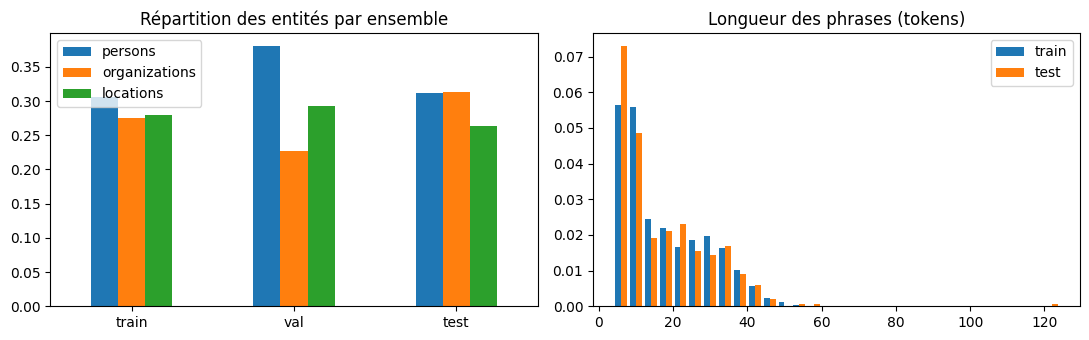

In [21]:
import matplotlib.pyplot as plt

lengths = {k: [len(r["text"].split()) for r in v] for k, v in splits.items()}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
counts = pd.DataFrame({k: v["entity_counts"] for k, v in manifest["splits"].items()}).T
(counts.drop(columns="sentences_without_entity").div(counts.sum(axis=1), axis=0)
       .plot.bar(ax=ax[0], title="Répartition des entités par ensemble", rot=0))
ax[1].hist([lengths["train"], lengths["test"]], bins=30, label=["train", "test"], density=True)
ax[1].set_title("Longueur des phrases (tokens)"); ax[1].legend()
plt.tight_layout(); plt.savefig("reports/data_overview.png", dpi=120)
for r in splits["train"][:3]: print(r["text"], "\n  →", r["entities"])

## 2. Baselines : même modèle, prompt seul (validation)

Le prompt système est **identique** pour toutes les variantes ; le few-shot ajoute k exemples tirés
du *train* uniquement. Baseline triviale à garder en tête : répondre toujours « vide » donne
une exact match égale à la part de phrases sans entité (~21 %) et un F1 de 0.

In [22]:
zero = pipeline.run_evaluation(cfg, "zero_shot", "val")
k = cfg.baseline.few_shot_k
few = pipeline.run_evaluation(cfg, f"few_shot{k}", "val", k_shots=k)
pd.DataFrame(pipeline.collect_metrics(cfg)).round(3)

generate:   0%|          | 0/19 [00:00<?, ?it/s]

generate:   0%|          | 0/19 [00:00<?, ?it/s]

,system,split,n,micro_f1,f1_ci95,precision,recall,exact_match,json_valid,strict_json,hallucination,s_per_example
0,few_shot3,val,300,0.605,"(0.5579567779960707, 0.6478405315614617)",0.627,0.584,0.303,0.997,0.997,0.062,0.214
1,qlora,val,300,0.871,"(0.8394618834080717, 0.9008695652173914)",0.907,0.839,0.730,1.000,1.000,0.015,0.369
2,zero_shot,val,300,0.383,"(0.3285870755750274, 0.4429223744292237)",0.602,0.281,0.303,0.997,0.000,0.147,0.182


## 3. Fine-tuning QLoRA (configuration principale : 1 500 exemples, 2 époques)

In [23]:
report = pipeline.run_training(cfg)
print({k: v for k, v in report.items() if k != "log_history"})

Step,Training Loss,Validation Loss
25,0.097300,0.075794
50,0.073000,0.052947
75,0.070500,0.042254
100,0.021500,0.039185
125,0.022400,0.034041
150,0.024600,0.031503
175,0.010300,0.030064


{'train_seconds': 789.9335827760005, 'parameters': {'trainable': 18464768, 'total': 907081216}, 'n_train': 1500, 'n_val': 300, 'dropped_too_long': {'train': 0, 'val': 0}, 'best_checkpoint': 'outputs/qwen1.5b-qlora-r16/checkpoints/checkpoint-175', 'best_eval_loss': 0.030064307153224945, 'peak_gpu_mem_gb': 7.276053504}


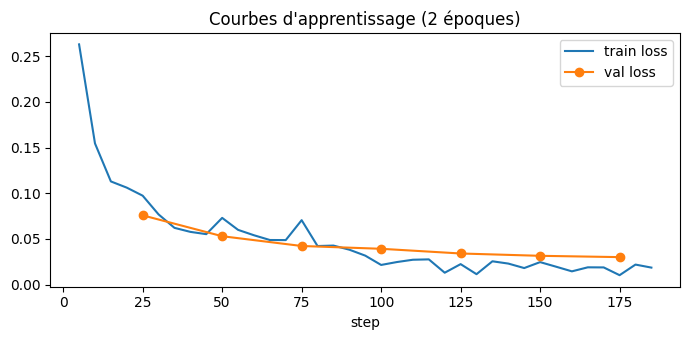

In [24]:
def plot_curves(report, title, path):
    log = pd.DataFrame(report["log_history"])
    fig, ax = plt.subplots(figsize=(7, 3.5))
    log.dropna(subset=["loss"]).plot(x="step", y="loss", ax=ax, label="train loss")
    log.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=ax, marker="o", label="val loss")
    ax.set_title(title); plt.tight_layout(); plt.savefig(path, dpi=120); plt.show()

plot_curves(report, "Courbes d'apprentissage (2 époques)", f"reports/{cfg.run_name}/learning_curves.png")

In [25]:
qlora = pipeline.run_evaluation(cfg, "qlora", "val", use_adapter=True)
ORDER = ["zero_shot", f"few_shot{k}", "qlora"]
table = pd.DataFrame(pipeline.collect_metrics(cfg)).query("split == 'val'").set_index("system").loc[ORDER]
table.round(3)

generate:   0%|          | 0/19 [00:00<?, ?it/s]

,split,n,micro_f1,f1_ci95,precision,recall,exact_match,json_valid,strict_json,hallucination,s_per_example
system,,,,,,,,,,,
zero_shot,val,300,0.383,"(0.3285870755750274, 0.4429223744292237)",0.602,0.281,0.303,0.997,0.000,0.147,0.182
few_shot3,val,300,0.605,"(0.5579567779960707, 0.6478405315614617)",0.627,0.584,0.303,0.997,0.997,0.062,0.214
qlora,val,300,0.866,"(0.8336594911937377, 0.895674300254453)",0.903,0.832,0.723,1.000,1.000,0.015,0.370


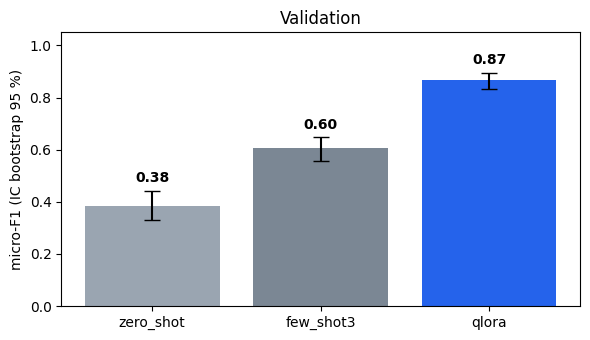

In [26]:
def plot_f1(table, title, path):
    fig, ax = plt.subplots(figsize=(6, 3.5))
    f1 = table["micro_f1"].astype(float)
    lo = f1 - table["f1_ci95"].map(lambda c: float(c[0]))
    hi = table["f1_ci95"].map(lambda c: float(c[1])) - f1
    ax.bar(table.index, f1, yerr=[lo, hi], capsize=6, color=["#9aa5b1", "#7b8794", "#2563eb"])
    for i, (v, top) in enumerate(zip(f1, f1 + hi)):
        ax.text(i, top + 0.02, f"{v:.2f}", ha="center", va="bottom", fontweight="bold")
    ax.set_ylabel("micro-F1 (IC bootstrap 95 %)"); ax.set_ylim(0, 1.05); ax.set_title(title)
    plt.tight_layout(); plt.savefig(path, dpi=120); plt.show()

plot_f1(table, "Validation", f"reports/{cfg.run_name}/f1_val.png")

## 4. Expériences de réglage et choix de la configuration finale (validation uniquement)

Chaque variante est une copie de la configuration avec un autre `run_name` : ses artefacts sont séparés.

* **4.a Quantité de données** : 100 / 500 / 1 500 exemples (`train.max_train_examples`).
* **4.b Durée d'entraînement** : 3 époques contre 2 (la perte de validation baissait encore à la fin
  de l'exécution de développement).
* **4.c Règle de choix, fixée avant de voir le test** : la configuration finale est celle des deux
  (2 ou 3 époques) qui a le **meilleur micro-F1 de validation** ; à égalité, la plus courte.

Step,Training Loss,Validation Loss


generate:   0%|          | 0/19 [00:00<?, ?it/s]

Step,Training Loss,Validation Loss
25,0.079100,0.076029
50,0.035500,0.058321


generate:   0%|          | 0/19 [00:00<?, ?it/s]

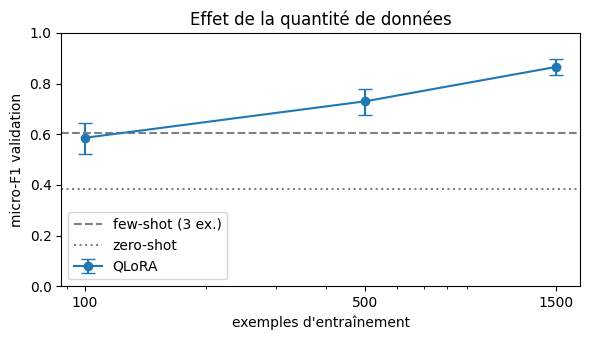

,n_train,micro_f1,ci95,hallucination
0,100,0.586,"(0.5230414746543779, 0.645220588235294)",0.039
1,500,0.730,"(0.6747230614300102, 0.7775831873905429)",0.017
2,1500,0.866,"(0.8336594911937377, 0.895674300254453)",0.015


In [27]:
from dataclasses import replace

def variant(name, **train_overrides):
    return replace(cfg, run_name=f"{cfg.run_name}-{name}", train=replace(cfg.train, **train_overrides))

ablation = []
for n in (100, 500):
    c = variant(f"n{n}", max_train_examples=n)
    pipeline.run_training(c)
    m = pipeline.run_evaluation(c, "qlora", "val", use_adapter=True)
    ablation.append({"n_train": n, "micro_f1": m["micro"]["f1"], "ci95": m["micro_f1_ci95"],
                     "hallucination": m["hallucination_rate"]})
ablation.append({"n_train": len(splits["train"]), "micro_f1": qlora["micro"]["f1"],
                 "ci95": qlora["micro_f1_ci95"], "hallucination": qlora["hallucination_rate"]})
ablation = pd.DataFrame(ablation)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(ablation["n_train"], ablation["micro_f1"], marker="o", capsize=5,
            yerr=[ablation["micro_f1"] - ablation["ci95"].map(lambda c: c[0]),
                  ablation["ci95"].map(lambda c: c[1]) - ablation["micro_f1"]], label="QLoRA")
ax.axhline(few["micro"]["f1"], ls="--", color="gray", label=f"few-shot ({k} ex.)")
ax.axhline(zero["micro"]["f1"], ls=":", color="gray", label="zero-shot")
ax.set_xscale("log"); ax.set_xticks(ablation["n_train"]); ax.set_xticklabels(ablation["n_train"])
ax.set_xlabel("exemples d'entraînement"); ax.set_ylabel("micro-F1 validation"); ax.set_ylim(0, 1)
ax.legend(); ax.set_title("Effet de la quantité de données")
plt.tight_layout(); plt.savefig(f"reports/{cfg.run_name}/data_size.png", dpi=120); plt.show()
ablation.round(3)

Step,Training Loss,Validation Loss
25,0.097000,0.085015
50,0.074000,0.056127
75,0.066000,0.047887
100,0.023600,0.038140
125,0.018000,0.032770
150,0.024900,0.030764
175,0.008600,0.027414
200,0.006000,0.026978
225,0.004600,0.028484
250,0.006600,0.028164


generate:   0%|          | 0/19 [00:00<?, ?it/s]

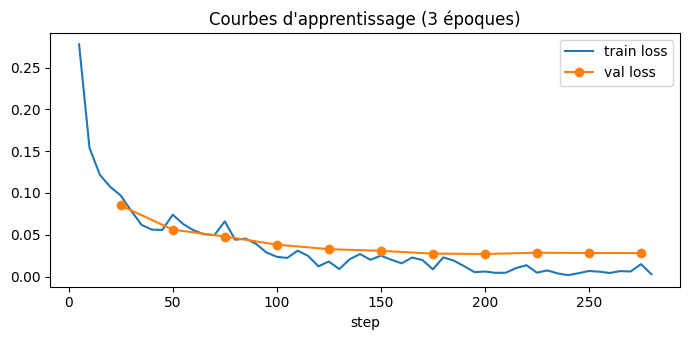

In [28]:
cfg_e3 = variant("e3", epochs=3)
report_e3 = pipeline.run_training(cfg_e3)
qlora_e3 = pipeline.run_evaluation(cfg_e3, "qlora", "val", use_adapter=True)
plot_curves(report_e3, "Courbes d'apprentissage (3 époques)", f"reports/{cfg_e3.run_name}/learning_curves.png")

In [29]:
candidates = {"2 époques": (cfg, qlora, report), "3 époques": (cfg_e3, qlora_e3, report_e3)}
summary = pd.DataFrame({name: {"micro_f1": m["micro"]["f1"], "ci95": tuple(round(x, 3) for x in m["micro_f1_ci95"]),
                               "best_val_loss": r["best_eval_loss"], "train_min": r["train_seconds"] / 60}
                        for name, (c, m, r) in candidates.items()}).T
display(summary)

# Règle 4.c : meilleur F1 de validation ; max() garde le premier (2 époques) en cas d'égalité
final_name = max(candidates, key=lambda name: candidates[name][1]["micro"]["f1"])
final_cfg, final_val, final_report = candidates[final_name]
print(f"Configuration finale retenue : {final_name}  (run '{final_cfg.run_name}')")

,micro_f1,ci95,best_val_loss,train_min
2 époques,0.865753,"(0.834, 0.896)",0.030064,13.16556
3 époques,0.9,"(0.874, 0.925)",0.026978,19.997916


Configuration finale retenue : 3 époques  (run 'qwen1.5b-qlora-r16-e3')


## 5. Analyse d'erreurs (validation, modèle final)

Taxonomie : `invalid_json`, `hallucination` (valeur absente du texte), `wrong_field` (bonne entité,
mauvais type), `boundary` (frontière trop longue/courte), `spurious` (pas une entité), `missed`.

In [30]:
from collections import Counter
from llmx.data.io import read_json, read_jsonl

def val_dir(c, system): return c.run_reports_dir / f"{system}_val"
systems = {"zero_shot": cfg, f"few_shot{k}": cfg, "qlora": final_cfg}
errors = pd.DataFrame({s: read_json(val_dir(c, s) / "metrics.json")["error_summary"] for s, c in systems.items()}).T
fields = pd.DataFrame({s: {f: v["f1"] for f, v in read_json(val_dir(c, s) / "metrics.json")["per_field"].items()}
                       for s, c in systems.items()}).T
display(errors); display(fields.round(3))

,invalid_json,hallucination,wrong_field,boundary,spurious,missed
zero_shot,1,39,37,6,24,368
few_shot3,1,33,64,11,90,163
qlora,0,6,12,5,12,58


,persons,organizations,locations
zero_shot,0.309,0.299,0.494
few_shot3,0.724,0.495,0.547
qlora,0.958,0.866,0.849


In [31]:
preds = read_jsonl(val_dir(final_cfg, "qlora") / "predictions.jsonl")

# Confusions de type : champ de référence -> champ prédit
confusions = Counter()
for p in preds:
    for e in p["errors"]:
        if e["category"] == "wrong_field":
            gold = next((f for f, vs in p["gold"].items() if e["value"] in [v.lower() for v in vs]), "?")
            confusions[f"{gold} -> {e['field']}"] += 1
print("Confusions de type :", dict(confusions))

# Titres en majuscules (dépêches sportives) contre le reste
def mostly_upper(t):
    words = [w for w in t.split() if w.isalpha()]
    return bool(words) and sum(w.isupper() for w in words) > 0.6 * len(words)
upper = [p for p in preds if mostly_upper(p["text"])]
rate = lambda rows: sum(bool(p["errors"]) for p in rows) / max(1, len(rows))
print(f"Phrases en majuscules : {len(upper)}, taux d'erreur {rate(upper):.0%} contre {rate(preds):.0%} au total")

Confusions de type : {'locations -> organizations': 4, 'organizations -> locations': 4, 'persons -> locations': 3, 'organizations -> persons': 1}
Phrases en majuscules : 17, taux d'erreur 41% contre 21% au total


In [32]:
wrong = [p for p in preds if p["errors"]]
print(f"{len(wrong)} phrases avec au moins une erreur sur {len(preds)}\n")
for p in wrong[:20]:
    print("TEXTE :", p["text"])
    print("  gold :", p["gold"])
    print("  pred :", p["pred"])
    print("  ->", [(e["category"], e["field"], e["value"]) for e in p["errors"]], "\n")

64 phrases avec au moins une erreur sur 300

TEXTE : Silver , basis the September contract on New York 's Comex market , was expected to find support at between $ 5.12 - $ 5.15 an ounce and meet resistance from $ 5.25 - $ 5.30 , they added .
  gold : {'persons': [], 'organizations': [], 'locations': ['New York']}
  pred : {'persons': [], 'organizations': ['Comex'], 'locations': ['New York']}
  -> [('spurious', 'organizations', 'comex')] 

TEXTE : The reports fanned worries on Wall Street that the Fed , the nation 's central bank , would raise rates next month in a bid to ward off inflation , driving stock and bond prices sharply lower for a second day running .
  gold : {'persons': [], 'organizations': ['Fed'], 'locations': ['Wall Street']}
  pred : {'persons': [], 'organizations': ['Fed'], 'locations': []}
  -> [('missed', 'locations', 'wall street')] 

TEXTE : Marriner said that NATO troops had set up a checkpoint on the road between Tuzla and Mahala to establish the identities and i

## 6. Évaluation finale sur le test — une seule fois par système

La configuration finale a été choisie en section 4 sur la validation. Les trois systèmes sont évalués
une fois chacun sur les 500 phrases de test ; une seconde exécution lève `HoldoutAlreadyUsedError`
(verrous dans `reports/test_locks/`).

generate:   0%|          | 0/32 [00:00<?, ?it/s]

generate:   0%|          | 0/32 [00:00<?, ?it/s]

generate:   0%|          | 0/32 [00:00<?, ?it/s]

,micro_f1,ci95,precision,recall,exact_match,strict_json,schema_valid,hallucination,s_per_example
zero_shot,0.392966,"(0.354, 0.431)",0.546809,0.306683,0.256,0.0,0.968,0.165957,0.182501
few_shot3,0.58033,"(0.545, 0.615)",0.594493,0.566826,0.33,0.998,0.652,0.051314,0.202242
qlora,0.901961,"(0.88, 0.921)",0.926952,0.878282,0.826,1.0,1.0,0.007557,0.303404


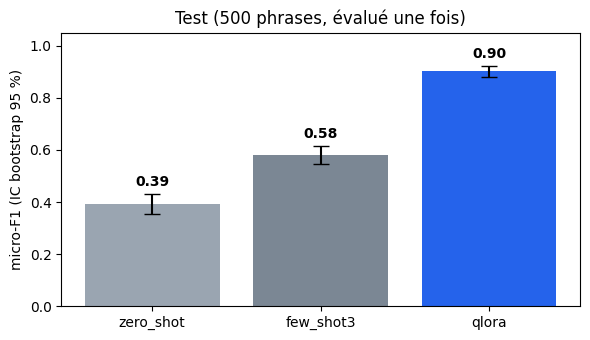

In [33]:
RUN_TEST = True   # exécution de remise finale

if RUN_TEST:
    test = {
        "zero_shot": pipeline.run_evaluation(cfg, "zero_shot", "test"),
        f"few_shot{k}": pipeline.run_evaluation(cfg, f"few_shot{k}", "test", k_shots=k),
        "qlora": pipeline.run_evaluation(final_cfg, "qlora", "test", use_adapter=True),
    }
    test_table = pd.DataFrame({
        s: {"micro_f1": m["micro"]["f1"], "ci95": tuple(round(x, 3) for x in m["micro_f1_ci95"]),
            "precision": m["micro"]["precision"], "recall": m["micro"]["recall"],
            "exact_match": m["exact_match"], "strict_json": m["strict_json_rate"],
            "schema_valid": m["schema_valid_rate"], "hallucination": m["hallucination_rate"],
            "s_per_example": m["seconds_per_example"]}
        for s, m in test.items()}).T
    display(test_table)
    plot_f1(test_table.assign(f1_ci95=test_table["ci95"]), "Test (500 phrases, évalué une fois)",
            f"reports/{final_cfg.run_name}/f1_test.png")
else:
    print("Test non évalué (RUN_TEST = False) : résultats de développement sur la validation uniquement.")

## 7. Analyse critique

> Chiffres de **test** (section 6, 500 phrases, évaluées une seule fois) pour la réponse à la question ;
> chiffres de **validation** pour les choix et l'analyse d'erreurs (sections 3 à 5). Exécution du
> 27/11/2026 sur un T4 Colab, commit `d2c2e78`.

### 7.1 Réponse à la question
Oui, et nettement. Sur le test, le modèle adapté par QLoRA (3 époques) atteint un micro-F1 de **0,90**
(IC 95 % : 0,88–0,92) contre **0,58** (0,55–0,62) pour le few-shot et **0,39** (0,35–0,43) pour le
zero-shot. Les intervalles de confiance sont très loin de se chevaucher : l'écart n'est pas un effet de
l'échantillon. L'exact match (toutes les entités d'une phrase correctes) passe de 0,33 à **0,83**.
Le gain s'obtient en entraînant **1,2 %** des paramètres (18,5 M sur 1,5 G) pendant **20 minutes** sur
un T4 gratuit ; l'adaptateur pèse 74 Mo.

| Test (500 phrases) | micro-F1 [IC 95 %] | précision | rappel | exact match | JSON strict | schéma valide | hallucinations | s / phrase |
|---|---|---|---|---|---|---|---|---|
| zero-shot | 0,393 [0,354–0,431] | 0,547 | 0,307 | 0,256 | 0 % | 96,8 % | 16,6 % | 0,18 |
| few-shot (3 ex.) | 0,580 [0,545–0,615] | 0,594 | 0,567 | 0,330 | 99,8 % | 65,2 % | 5,1 % | 0,20 |
| **QLoRA (3 époques)** | **0,902 [0,880–0,921]** | **0,927** | **0,878** | **0,826** | **100 %** | **100 %** | **0,8 %** | 0,30 |

**Choix de la configuration.** Par la règle 4.c, les 3 époques (F1 de validation 0,900, IC 0,874–0,925)
l'emportent sur les 2 époques (0,866, IC 0,834–0,896). Les IC se recouvrent : cette préférence est
fragile, mais elle est cohérente avec la perte de validation (0,027 contre 0,030 ; meilleur point au
pas 200 sur 282). Le F1 de test (0,902) est presque identique au F1 de validation (0,900) : le choix
sur la validation n'a pas produit d'optimisme mesurable.

### 7.2 Le format compte autant que l'exactitude
* **Zero-shot** : le modèle entoure systématiquement son JSON d'un bloc Markdown (```` ```json ````) :
  0 % de JSON strict. Sans analyseur tolérant, aucune réponse ne serait exploitable par un programme.
* **Few-shot** : JSON strict, mais **35 %** des réponses de test violent le schéma (clés vides omises
  dans 173 réponses, clés inventées comme `dates`, `numbers` ou `events`) alors que les trois
  exemples montrent le schéma exact.
* **QLoRA** : 100 % de JSON strict et de schéma valide, sur la validation comme sur le test. Le
  fine-tuning apprend le *contrat de sortie*, pas seulement la tâche.

### 7.3 Hallucinations
Le taux de valeurs absentes du texte passe de 16,6 % (zero-shot) à 5,1 % (few-shot) puis **0,8 %**
(QLoRA, 6 valeurs sur 794 prédites).
* En zero-shot, ce sont surtout des **inférences** : « India » pour *Bombay Commodities*, « Israel »
  pour *Israeli crews*. Le modèle raisonne avec ses connaissances au lieu d'extraire.
* Sur les 6 cas QLoRA du test, trois sont des **faux positifs de la métrique** : la comparaison se
  fait par mots entiers et CoNLL garde les mots composés en un seul jeton (« USDA » dans *sales-USDA*,
  « Mississippi » dans *mid-Mississippi*, « Arafat » dans *Arafat-Netanyahu*). Deux sont des
  **normalisations** : « Belarus » pour *Belorus*, « World Trade Organisation (WTO) » reconstruit.
  Une seule est une vraie invention : « Leah », déformation de *Lahd*, classé en lieu.

### 7.4 Où le modèle se trompe encore
* Les oublis dominent (69 des 127 erreurs de test) : le modèle est plus **précis** (0,93) que
  **complet** (0,88). Ils se concentrent dans les tableaux et listes (compositions d'équipes,
  résultats) et sur les adjectifs (« Czech » President).
* Les **personnes** sont faciles (F1 test 0,96) ; **organisations** et **lieux** plafonnent à 0,87.
  Les confusions de type viennent surtout des conventions d'annotation : un lieu qui désigne une équipe
  (lieu → organisation : 11 cas sur le test, par ex. « Portsmouth », « Syria » dans un classement,
  « West Indies » au cricket).
* Une partie des faux positifs vient de **notre choix d'écarter MISC** : le modèle extrait
  « JCPenney Classic » ou « Pilkington Cup », qui sont des MISC dans CoNLL.
* **Titres en majuscules** : sur la validation, le modèle final s'y trompait deux fois plus souvent
  (41 % contre 21 %), mais sur 17 phrases seulement. Le test **ne confirme pas** l'effet pour QLoRA
  (15 % contre 17 %, 46 phrases), alors qu'il est massif pour les baselines (89 % d'erreurs contre
  67 à 74 %). Le fine-tuning semble avoir appris à ne plus dépendre de la casse ; c'est aussi un
  rappel qu'une observation sur une vingtaine de phrases n'est qu'une piste.

### 7.5 Quantité de données et coût
Avec 100 exemples, le F1 de validation (0,59) rejoint le few-shot (0,61, IC qui se recouvrent) ;
500 exemples donnent 0,73 et 1 500 donnent 0,87 (0,90 avec 3 époques). La courbe ne plafonne pas :
davantage de données annotées serait le levier le plus rentable.
Coût à l'inférence : 0,30 s par phrase contre 0,18 s sans adaptateur, car l'adaptateur n'est pas
fusionné dans le modèle ; une fusion (`merge_and_unload`) supprimerait ce surcoût.

### 7.6 Limites
* **Un seul domaine** : dépêches Reuters en anglais de 1996. Rien ne garantit la généralisation à
  d'autres langues, époques ou registres (réseaux sociaux, documents administratifs).
* **Une seule graine** : les IC bootstrap mesurent la variabilité due à l'échantillon de phrases,
  pas celle de l'entraînement ; l'écart 2 / 3 époques est du même ordre que cette variabilité.
* **Baselines non optimisées** : le prompt n'a pas été travaillé (pas de recherche de prompt,
  exemples few-shot tirés au hasard) ; l'écart mesuré est un majorant face à un prompt soigné.
* **Évaluation par chaîne exacte** (après minuscules et espaces) : une variante correcte
  (« U.S. » / « US ») compte comme une erreur ; étiquettes CoNLL elles-mêmes partiellement bruitées.
* **MISC écarté** : simplifie la tâche mais crée des faux positifs (7.4).
* **Exécution** : le noyau Colab venait d'une session précédente et avait gardé en mémoire l'ancienne
  version du paquet `llmx`. L'entraînement a donc tourné sans la réduction automatique de
  l'intervalle d'évaluation pour les exécutions courtes. Sans effet sur les exécutions principales
  (188 et 282 pas, intervalle de 25 dans les deux versions), donc ni sur le choix final ni sur le test.
  En revanche, l'ablation à 100 exemples (14 pas) n'a pas été évaluée en cours d'entraînement : son
  point est le dernier état, pas le meilleur, et son F1 est peut-être légèrement sous-estimé. Pour la
  même raison, `peak_gpu_mem_gb` est un maximum cumulé sur le noyau (corrigé depuis) : seule la
  valeur du premier entraînement (7,3 Go) est fiable. Enfin, le tableau de la section 2 affiche une
  ligne `qlora` (0,871) issue du rapport de développement présent dans le dépôt cloné ; la valeur de
  cette exécution est celle de la section 3 (0,866).

### 7.7 Éthique et risques
* **Données personnelles** : extraire automatiquement des noms de personnes relève du RGPD dès qu'on
  l'applique à des documents réels ; un tel outil peut servir au profilage ou à la surveillance.
* **Biais** : le corpus surreprésente l'actualité occidentale, politique et sportive de 1996, et des
  personnes majoritairement masculines ; les performances sur d'autres noms (non occidentaux,
  translittérés) ne sont pas mesurées.
* **Confiance trompeuse** : un JSON toujours valide inspire confiance alors que 12 % des entités
  sont encore manquées et que des erreurs de type subsistent ; une validation humaine reste nécessaire.
* **Licences et sobriété** : modèle sous licence Apache 2.0 ; textes CoNLL/Reuters non redistribués
  dans le dépôt (seules les empreintes le sont) ; environ 38 minutes de GPU T4 pour les quatre
  entraînements.

## 8. Sauvegarde des résultats

In [34]:
# Archive des métriques, figures, journaux et adaptateurs LoRA (à recopier dans le dépôt)
!cd {ROOT} && zip -qr {BASE}/results.zip reports outputs/*/adapter && ls -lh {BASE}/results.zip
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(str(BASE / "results.zip"))
else:
    print("Kaggle : results.zip est disponible dans l'onglet Output du notebook.")

-rw-r--r-- 1 root root 277M Nov 27 14:26 /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>